# Analysis of Arabic MCQ Surveys

## 1. Setup and Imports

In [1]:
import os
import random
import re
import pandas as pd
import matplotlib.pyplot as plt
import arabic_reshaper
from bidi.algorithm import get_display
from matplotlib import font_manager
import seaborn as sns
import missingno as msno
import numpy as np
from dotenv import load_dotenv
from Kobo.kobo_toolbox_client import KoboToolboxClient
from Kobo.kobo_form_builder import KoboFormBuilder
from Kobo.kobo_form_uploader import KoboFormUploader
import featuretools as ft

c:\Users\eyasw\OneDrive\Desktop\Gra\analytics-of-arabic-mcq-surveys\.venv\Lib\site-packages\woodwork\__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


### 1.1 Configure Environment
Load environment variables from a `.env` file. This is where you should store your API token securely.

In [2]:
load_dotenv()

True

### 1.2 Configure Arabic Font for Plots

In [3]:
font_path = 'C:/Windows/Fonts/arial.ttf'  # Change this to a font that supports Arabic
if os.path.exists(font_path):
    prop = font_manager.FontProperties(fname=font_path)
    plt.rcParams['font.family'] = prop.get_name()
else:
    print(f'Font not found at {font_path}. Please update the path.')

## 2. KoboToolbox Integration

### 2.1 Initialize KoboToolbox Client
The client is initialized using the URL and API token from your environment variables.

In [ ]:
KOBO_API_URL = os.getenv("KOBO_API_URL", "https://kf.kobotoolbox.org/")
KOBO_API_TOKEN = os.getenv("KOBO_API_TOKEN", '')

if not KOBO_API_TOKEN:
    raise ValueError("KOBO_API_TOKEN not found in environment variables. Please set it in your .env file.")

kobo_client = KoboToolboxClient(
	url=KOBO_API_URL,
	token=KOBO_API_TOKEN
)

### 2.2 Create a New Survey Form

In [5]:
builder = KoboFormBuilder('استبيان رضا المستفيدين')

# Section 1: Demographic Questions
builder.add_select_question(name='gender', label='ما هو جنسك؟', options=['ذكر', 'أنثى'], required=True)
builder.add_select_question(name='age_group', label='ما هو فئتك العمرية؟', options=['أقل من 18', '18-24', '25-34', '35-44', '45 فأكثر'], required=True)
builder.add_select_question(name='governorate', label='في أي محافظة تعيش؟', options=['دمشق', 'ريف دمشق', 'حلب', 'حمص', 'حماة', 'اللاذقية', 'طرطوس', 'إدلب', 'درعا', 'القنيطرة', 'دير الزور', 'الحسكة', 'الرقة', 'السويداء'], required=True)
builder.add_select_question(name='education_level', label='ما هو مستواك التعليمي؟', options=['ثانوي أو أقل', 'دبلوم', 'بكالوريوس', 'ماجستير', 'دكتوراه'], required=True)
builder.add_select_question(name='employment_status', label='ما هو وضعك الوظيفي؟', options=['طالب', 'موظف', 'باحث عن عمل', 'عمل حر', 'أخرى'], required=True)
builder.add_select_question(name='specialization', label='ما هو تخصصك الأكاديمي؟', options=['هندسة حاسوب', 'ذكاء اصطناعي', 'إدارة أعمال', 'اقتصاد', 'علوم اجتماعية', 'تربية', 'أخرى'], required=False)

# Section 2: Satisfaction Measurement
builder.add_select_question(name='satisfaction_overall', label='كيف تقيم تجربتك العامة مع الخدمات التي حصلت عليها؟', options=['راضٍ جدًا', 'راضٍ', 'محايد', 'غير راضٍ', 'غير راضٍ أبدًا'], required=True)
builder.add_select_question(name='satisfaction_access', label='ما مدى سهولة الوصول إلى الخدمات المقدمة؟', options=['سهل جدًا', 'سهل', 'متوسط', 'صعب', 'صعب جدًا'], required=True)
builder.add_select_question(name='satisfaction_support', label='ما مدى جودة الدعم الذي حصلت عليه أثناء استخدام الخدمة؟', options=['ممتاز', 'جيد جدًا', 'جيد', 'ضعيف', 'سيء جدًا'], required=True)
builder.add_select_question(name='suggestions', label='هل لديك اقتراحات لتحسين الخدمات؟', options=['نعم، لدي اقتراح', 'لا يوجد لدي اقتراح'], required=False)

form_json = builder.to_json()
print("Form JSON created successfully.")

Form JSON created successfully.


### 2.3 Upload and Deploy the Form
This step will create and deploy the form on KoboToolbox. You only need to run this once.

In [6]:
uploader = KoboFormUploader(api_url=KOBO_API_URL, token=KOBO_API_TOKEN)

# try:
#     # 1) Create the form
#     result = uploader.create_form(form_json, builder.title)
#     form_uid = result.get('uid') or result.get('id')
#     print(f"Form created with UID: {form_uid}")

#     # 2) Deploy the form
#     deployment = uploader.deploy_form(form_uid)
#     print(f"Form deployed successfully. Identifier: {deployment.get('identifier')}")
# except Exception as e:
#     print(f"An error occurred during form upload/deployment: {e}")

## 3. Data Retrieval and Analysis

### 3.1 Fetch Submissions from KoboToolbox

In [7]:
try:
    forms = kobo_client.get_all_forms()
    if forms:
        first_form_uid = forms[1].uid
        print(f"Fetching submissions for form: {forms[1].name} ({first_form_uid})")
        submissions_df = kobo_client.get_submissions(first_form_uid)
        display(submissions_df.tail(20))
    else:
        print("No forms found.")
except Exception as e:
    print(f'\nError occurred while fetching submissions: {e}')

Fetching submissions for form: MEAL_Survey_Form (ac9KArL9Nyvrg855zo7E24)


,_id,formhub/uuid,ما هو جنسك؟,إلى أي فئة عمرية تنتمي؟,في أي محافظة تقيم؟,ما هو أعلى مستوى تعليمي حصلت عليه؟,ما هي حالتك الوظيفية حاليًا؟,هل لديك أي إعاقة؟,هل شاركت في نشاط البرنامج؟,ما مدى رضاك العام عن النشاط؟,...,_uuid,meta/rootUuid,_attachments,_status,_geolocation,_submission_time,_tags,_notes,_validation_status,_submitted_by
80,514642341,4d54999bc0f74d89a35ab14126086f1b,أنثى,25-34,الأقصر,ثانوي,طالب,نعم,نعم,غير راضٍ إطلاقًا,...,723e2c7d-6cf9-4e6b-a35a-22049c41dfc9,uuid:723e2c7d-6cf9-4e6b-a35a-22049c41dfc9,[],submitted_via_web,"[None, None]",2025-07-10T19:28:06,[],[],{},None
81,514642619,4d54999bc0f74d89a35ab14126086f1b,ذكر,18-24,سوهاج,جامعي,دوام جزئي,نعم,لا,راضٍ,...,fd38ac5c-90cd-41ec-adee-60284c78f99c,uuid:fd38ac5c-90cd-41ec-adee-60284c78f99c,[],submitted_via_web,"[None, None]",2025-07-10T19:28:37,[],[],{},None
82,514642919,4d54999bc0f74d89a35ab14126086f1b,أنثى,35-44,سوهاج,ثانوي,دوام جزئي,نعم,نعم,غير راضٍ,...,81b537dd-76db-4b91-86ef-0f2706abdc78,uuid:81b537dd-76db-4b91-86ef-0f2706abdc78,[],submitted_via_web,"[None, None]",2025-07-10T19:29:24,[],[],{},None
83,514643127,4d54999bc0f74d89a35ab14126086f1b,أنثى,55+,الجيزة,دراسات عليا,طالب,لا,نعم,محايد,...,1a70fa9a-08d7-4a96-a59f-373e42612a50,uuid:1a70fa9a-08d7-4a96-a59f-373e42612a50,[],submitted_via_web,"[None, None]",2025-07-10T19:29:55,[],[],{},None
84,514643330,4d54999bc0f74d89a35ab14126086f1b,ذكر,45-54,سوهاج,ابتدائي,طالب,لا,نعم,راضٍ,...,8b18e962-95a0-4a77-ba91-e2f546e0c6d7,uuid:8b18e962-95a0-4a77-ba91-e2f546e0c6d7,[],submitted_via_web,"[None, None]",2025-07-10T19:30:25,[],[],{},None
85,514643529,4d54999bc0f74d89a35ab14126086f1b,أنثى,25-34,الجيزة,ثانوي,طالب,نعم,نعم,غير راضٍ,...,b88af236-f2e1-4a23-a3dd-776f86b8c1e5,uuid:b88af236-f2e1-4a23-a3dd-776f86b8c1e5,[],submitted_via_web,"[None, None]",2025-07-10T19:30:52,[],[],{},None
86,514643773,4d54999bc0f74d89a35ab14126086f1b,ذكر,45-54,سوهاج,جامعي,لا يعمل,نعم,لا,غير راضٍ,...,a51dbc6b-a5f3-4dd3-8521-640ea1ecb726,uuid:a51dbc6b-a5f3-4dd3-8521-640ea1ecb726,[],submitted_via_web,"[None, None]",2025-07-10T19:31:23,[],[],{},None
87,514643965,4d54999bc0f74d89a35ab14126086f1b,ذكر,25-34,الأقصر,جامعي,طالب,لا,نعم,محايد,...,535b62a9-dd0f-4e95-94aa-8b8f635a8edf,uuid:535b62a9-dd0f-4e95-94aa-8b8f635a8edf,[],submitted_via_web,"[None, None]",2025-07-10T19:31:50,[],[],{},None
88,514644153,4d54999bc0f74d89a35ab14126086f1b,أنثى,45-54,سوهاج,دراسات عليا,دوام كامل,لا,لا,راضٍ,...,f6e76da8-30c2-46cc-91fe-daacd9e359ad,uuid:f6e76da8-30c2-46cc-91fe-daacd9e359ad,[],submitted_via_web,"[None, None]",2025-07-10T19:32:21,[],[],{},None
89,514644365,4d54999bc0f74d89a35ab14126086f1b,ذكر,35-44,الأقصر,جامعي,لا يعمل,نعم,لا,غير راضٍ,...,f1ae5069-aa98-438c-82e7-faeddd8054aa,uuid:f1ae5069-aa98-438c-82e7-faeddd8054aa,[],submitted_via_web,"[None, None]",2025-07-10T19:32:50,[],[],{},None


### 3.2 Map Coded Answers to Labels

In [8]:
def map_answers_to_labels(kobo_client : KoboToolboxClient, form_uid : str, submissions_df : pd.DataFrame):
    """Maps coded answers in a DataFrame to their human-readable labels."""
    try:
        form_details = kobo_client.get_form_details(form_uid)
        
        # Create a mapping from choice list names to their options
        choice_map = {}
        for choice in form_details.get('choices', []):
            list_name = choice.get('list_name')
            if list_name not in choice_map:
                choice_map[list_name] = {}
            choice_map[list_name][choice.get('name')] = choice.get('label', [None])[0]

        # Create a mapping from question names to their choice maps
        question_map = {}
        for question in form_details.get('survey', []):
            if question.get('type') in ['select_one', 'select_multiple']:
                list_name = question.get('select_from_list_name')
                if list_name in choice_map:
                    question_map[question.get('name')] = choice_map[list_name]

        # Apply the mapping to the DataFrame
        df_labeled = submissions_df.copy()
        for col, mapping in question_map.items():
            if col in df_labeled.columns:
                df_labeled[col] = df_labeled[col].map(mapping)
        
        return df_labeled

    except Exception as e:
        print(f"An error occurred while mapping answers: {e}")
        return submissions_df # Return original df on error

if 'submissions_df' in locals() and not submissions_df.empty:
    submissions_labeled_df = map_answers_to_labels(kobo_client, first_form_uid, submissions_df)
    print("DataFrame with human-readable labels:")
    display(submissions_labeled_df.head())
else:
    print("Submissions DataFrame is not available or is empty.")

DataFrame with human-readable labels:


,_id,formhub/uuid,ما هو جنسك؟,إلى أي فئة عمرية تنتمي؟,في أي محافظة تقيم؟,ما هو أعلى مستوى تعليمي حصلت عليه؟,ما هي حالتك الوظيفية حاليًا؟,هل لديك أي إعاقة؟,هل شاركت في نشاط البرنامج؟,ما مدى رضاك العام عن النشاط؟,...,_uuid,meta/rootUuid,_attachments,_status,_geolocation,_submission_time,_tags,_notes,_validation_status,_submitted_by
0,513700501,4d54999bc0f74d89a35ab14126086f1b,ذكر,18-24,القاهرة,إعدادي,دوام كامل,لا,نعم,راضٍ,...,8e5bb245-a622-4734-944e-8c28a16d9295,uuid:8e5bb245-a622-4734-944e-8c28a16d9295,[],submitted_via_web,"[None, None]",2025-07-09T18:26:33,[],[],{},None
1,513700707,4d54999bc0f74d89a35ab14126086f1b,ذكر,45-54,أسوان,إعدادي,دوام جزئي,لا,نعم,محايد,...,c8841cfa-fec2-4e13-8b42-41563cb62316,uuid:c8841cfa-fec2-4e13-8b42-41563cb62316,[],submitted_via_web,"[None, None]",2025-07-09T18:27:09,[],[],{},None
2,513700893,4d54999bc0f74d89a35ab14126086f1b,أنثى,18-24,القاهرة,ابتدائي,دوام كامل,نعم,نعم,غير راضٍ,...,a39260b4-65b3-4c42-9114-5f58e7ddbdbe,uuid:a39260b4-65b3-4c42-9114-5f58e7ddbdbe,[],submitted_via_web,"[None, None]",2025-07-09T18:27:36,[],[],{},None
3,513701064,4d54999bc0f74d89a35ab14126086f1b,ذكر,15-17,الإسكندرية,إعدادي,طالب,نعم,لا,راضٍ,...,11ec1585-0380-4f8b-89a2-72c54d1ecaef,uuid:11ec1585-0380-4f8b-89a2-72c54d1ecaef,[],submitted_via_web,"[None, None]",2025-07-09T18:28:06,[],[],{},None
4,513705325,4d54999bc0f74d89a35ab14126086f1b,ذكر,15-17,الإسكندرية,ثانوي,طالب,لا,لا,راضٍ جدًا,...,5635b465-a1cb-4e3a-bcb2-c28f509491b4,uuid:5635b465-a1cb-4e3a-bcb2-c28f509491b4,[],submitted_via_web,"[None, None]",2025-07-09T18:36:14,[],[],{},None


### 3.3 Exploratory Data Analysis (EDA)

Dataset Shape: (100, 40)

Missing Values:


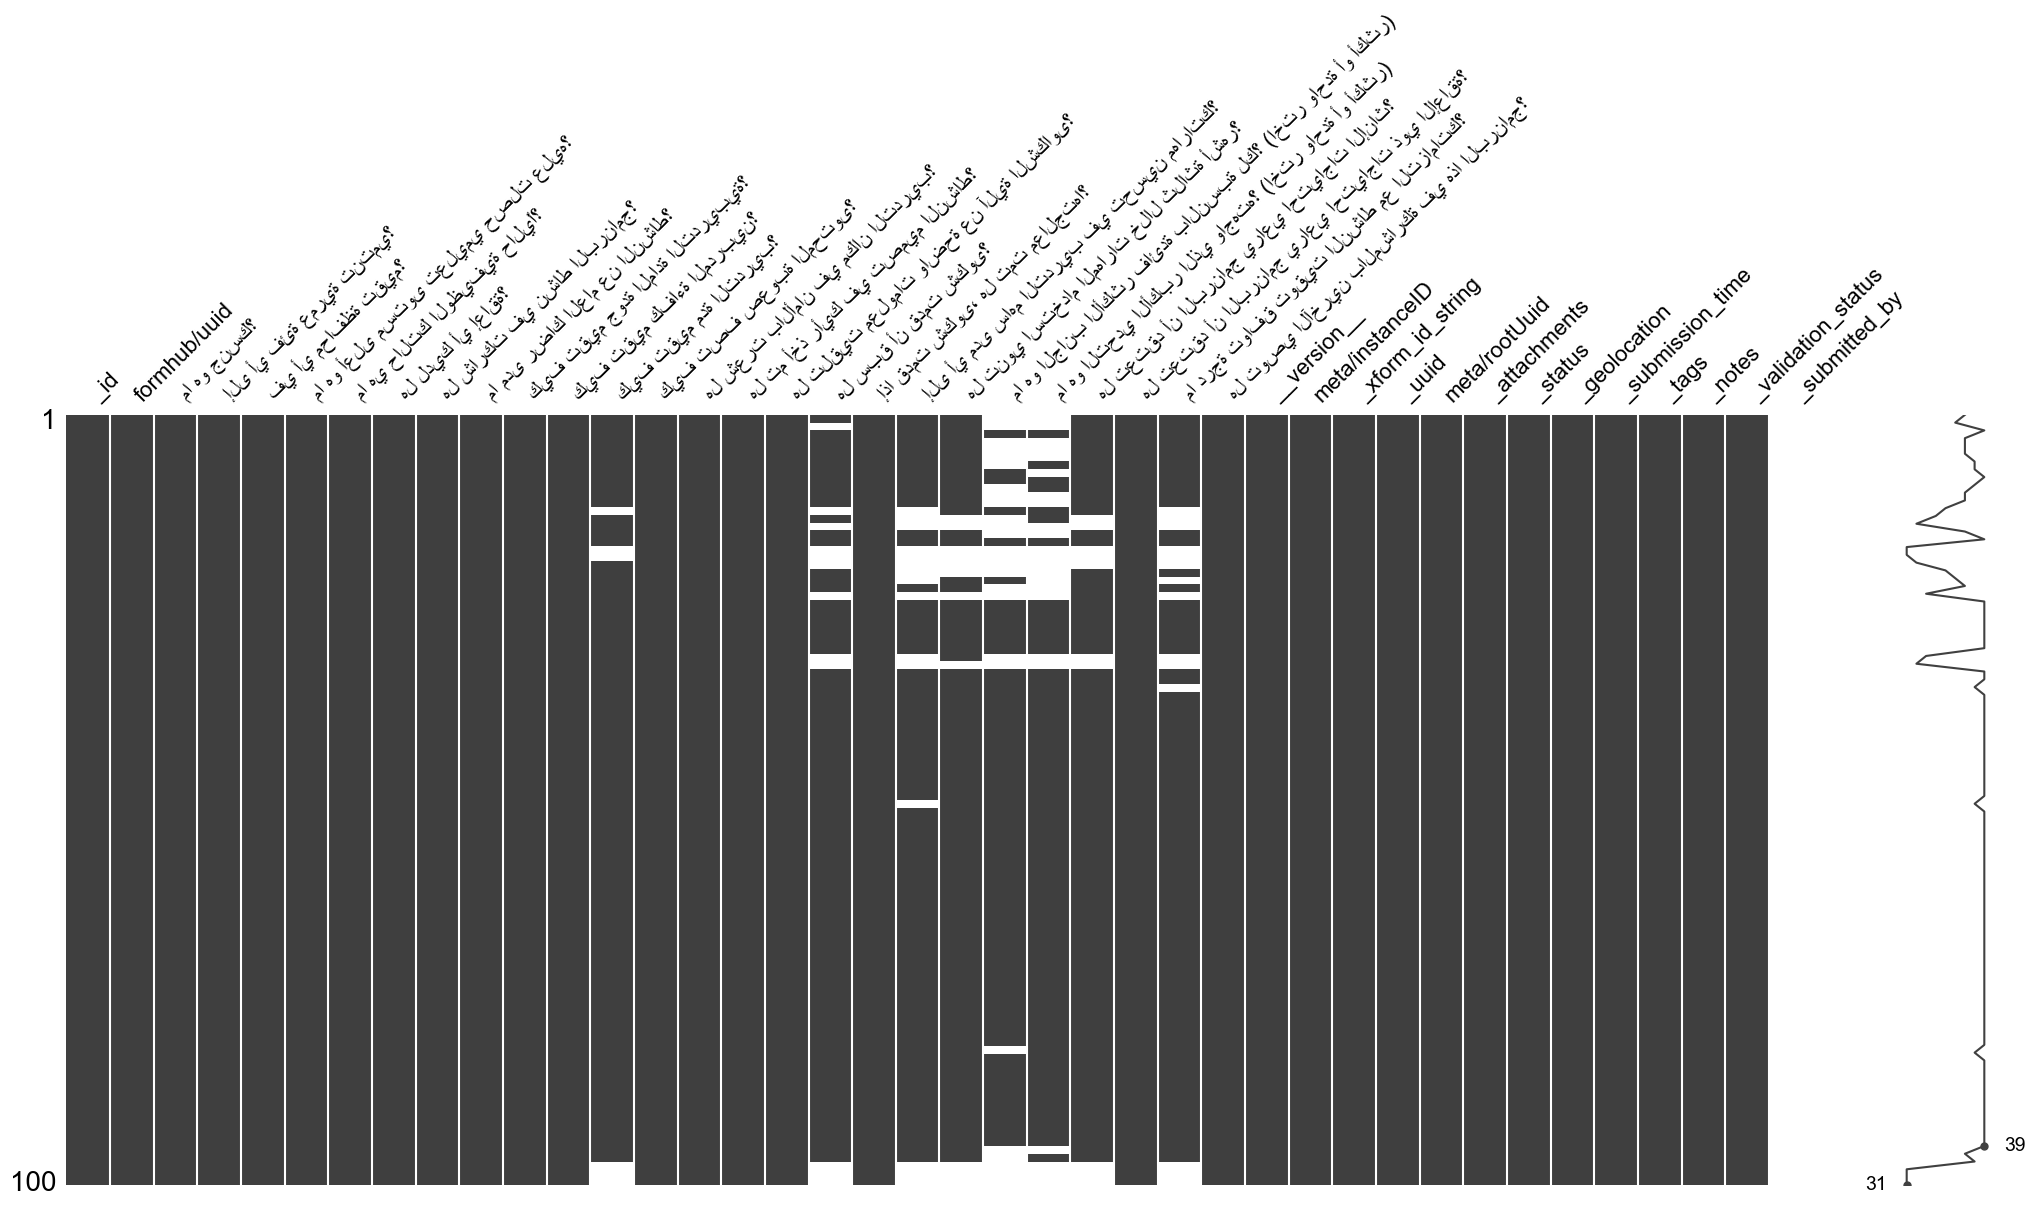

In [9]:
if 'submissions_labeled_df' in locals() and not submissions_labeled_df.empty:
    print("Dataset Shape:", submissions_labeled_df.shape)
    print("\nMissing Values:")
    msno.matrix(submissions_labeled_df)
    plt.show()
else:
    print("Labeled submissions DataFrame is not available or is empty.")

In [10]:
# def plot_arabic_bar(data, column, title):
#     """Helper function to plot bar charts with Arabic labels."""
#     plt.figure(figsize=(10, 6))
#     ax = sns.countplot(y=data[column], order=data[column].value_counts().index)
    
#     # Reshape and display Arabic labels correctly
#     ax.set_yticklabels([get_display(arabic_reshaper.reshape(label.get_text())) for label in ax.get_yticklabels()])
    
#     plt.title(get_display(arabic_reshaper.reshape(title)))
#     plt.xlabel(get_display(arabic_reshaper.reshape('العدد')))
#     plt.ylabel('')
#     plt.tight_layout()
#     plt.show()

# if 'submissions_labeled_df' in locals() and not submissions_labeled_df.empty:
#     plot_arabic_bar(submissions_labeled_df, 'gender', 'توزيع المشاركين حسب الجنس')
#     plot_arabic_bar(submissions_labeled_df, 'age_group', 'توزيع المشاركين حسب الفئة العمرية')
#     plot_arabic_bar(submissions_labeled_df, 'governorate', 'توزيع المشاركين حسب المحافظة')
# else:
#     print("Labeled submissions DataFrame is not available or is empty.")

## 4. Automated Feature Engineering

In [11]:
if 'submissions_labeled_df' in locals() and not submissions_labeled_df.empty:
    # Create an EntitySet
    es = ft.EntitySet(id="survey_data")

    # Add the submissions dataframe to the EntitySet
    es = es.add_dataframe(
        dataframe_name="submissions", 
        dataframe=submissions_labeled_df, 
        index="_index",
        time_index="_submission_time"
    )

    # Run Deep Feature Synthesis (DFS)
    feature_matrix, feature_defs = ft.dfs(
        entityset=es,
        target_dataframe_name="submissions",
        agg_primitives=["count", "sum", "mean", "std", "skew", "min", "max", "mode"],
        trans_primitives=["day", "year", "month", "weekday", "is_weekend"],
        max_depth=2
    )

    print("Feature matrix shape:", feature_matrix.shape)
    display(feature_matrix.head())

else:
    print("Labeled submissions DataFrame is not available or is empty.")

c:\Users\eyasw\OneDrive\Desktop\Gra\analytics-of-arabic-mcq-surveys\.venv\Lib\site-packages\featuretools\entityset\entityset.py:1733: UserWarning: index _index not found in dataframe, creating new integer column
  warnings.warn(
c:\Users\eyasw\OneDrive\Desktop\Gra\analytics-of-arabic-mcq-surveys\.venv\Lib\site-packages\woodwork\type_sys\utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
c:\Users\eyasw\OneDrive\Desktop\Gra\analytics-of-arabic-mcq-surveys\.venv\Lib\site-packages\woodwork\type_sys\utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
c:\Users\eyasw\OneDrive\Desktop\Gra\analytics-of-arabic-mcq-surveys\.venv\Lib\site-packages\woodwork\type_sys\utils.py:33

Feature matrix shape: (100, 35)


c:\Users\eyasw\OneDrive\Desktop\Gra\analytics-of-arabic-mcq-surveys\.venv\Lib\site-packages\woodwork\type_sys\utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
c:\Users\eyasw\OneDrive\Desktop\Gra\analytics-of-arabic-mcq-surveys\.venv\Lib\site-packages\woodwork\type_sys\utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
c:\Users\eyasw\OneDrive\Desktop\Gra\analytics-of-arabic-mcq-surveys\.venv\Lib\site-packages\woodwork\type_sys\utils.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(
c:\Users\eyasw\OneDrive\D

,_id,formhub/uuid,ما هو جنسك؟,إلى أي فئة عمرية تنتمي؟,في أي محافظة تقيم؟,ما هو أعلى مستوى تعليمي حصلت عليه؟,ما هي حالتك الوظيفية حاليًا؟,هل لديك أي إعاقة؟,هل شاركت في نشاط البرنامج؟,ما مدى رضاك العام عن النشاط؟,...,ما درجة توافق توقيت النشاط مع التزاماتك؟,هل توصي الآخرين بالمشاركة في هذا البرنامج؟,__version__,_xform_id_string,_status,DAY(_submission_time),IS_WEEKEND(_submission_time),MONTH(_submission_time),WEEKDAY(_submission_time),YEAR(_submission_time)
_index,,,,,,,,,,,,,,,,,,,,,
0,513700501,4d54999bc0f74d89a35ab14126086f1b,ذكر,18-24,القاهرة,إعدادي,دوام كامل,لا,نعم,راضٍ,...,مناسب,غير متأكد,vSp9GXofMs2dpkrWYdMXfn,ac9KArL9Nyvrg855zo7E24,submitted_via_web,9,False,7,2,2025
1,513700707,4d54999bc0f74d89a35ab14126086f1b,ذكر,45-54,أسوان,إعدادي,دوام جزئي,لا,نعم,محايد,...,محايد,ربما,vSp9GXofMs2dpkrWYdMXfn,ac9KArL9Nyvrg855zo7E24,submitted_via_web,9,False,7,2,2025
2,513700893,4d54999bc0f74d89a35ab14126086f1b,أنثى,18-24,القاهرة,ابتدائي,دوام كامل,نعم,نعم,غير راضٍ,...,محايد,أكيد,vSp9GXofMs2dpkrWYdMXfn,ac9KArL9Nyvrg855zo7E24,submitted_via_web,9,False,7,2,2025
3,513701064,4d54999bc0f74d89a35ab14126086f1b,ذكر,15-17,الإسكندرية,إعدادي,طالب,نعم,لا,راضٍ,...,مناسب,أكيد,vSp9GXofMs2dpkrWYdMXfn,ac9KArL9Nyvrg855zo7E24,submitted_via_web,9,False,7,2,2025
4,513705325,4d54999bc0f74d89a35ab14126086f1b,ذكر,15-17,الإسكندرية,ثانوي,طالب,لا,لا,راضٍ جدًا,...,مناسب,أكيد,vSp9GXofMs2dpkrWYdMXfn,ac9KArL9Nyvrg855zo7E24,submitted_via_web,9,False,7,2,2025
